## The Breast Cancer Wisconsin dataset (continued)

In [1]:
import pandas as pd

df = pd.read_csv('https://archive.ics.uci.edu/ml/'
                 'machine-learning-databases'
                 '/breast-cancer-wisconsin/wdbc.data', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
df.shape

(569, 32)

### Create class response and relabel

In [3]:
from sklearn.preprocessing import LabelEncoder

X = df.loc[:, 2:].values
y = df.loc[:, 1].values
le = LabelEncoder()
y = le.fit_transform(y)
le.classes_

array(['B', 'M'], dtype=object)

In [4]:
le.transform(['M', 'B'])

array([1, 0])

### Split into training and test

In [5]:
from sklearn.model_selection import train_test_split

[X_train, X_test, y_train, y_test] = train_test_split(X, y, test_size=0.20, stratify=y, random_state=1)

## [Grid search](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Define the pipeline (scaling and classification method):
pipe_svc = make_pipeline(StandardScaler(), SVC(random_state=1))
pipe_svc.get_params()

{'memory': None,
 'steps': [('standardscaler', StandardScaler()), ('svc', SVC(random_state=1))],
 'transform_input': None,
 'verbose': False,
 'standardscaler': StandardScaler(),
 'svc': SVC(random_state=1),
 'standardscaler__copy': True,
 'standardscaler__with_mean': True,
 'standardscaler__with_std': True,
 'svc__C': 1.0,
 'svc__break_ties': False,
 'svc__cache_size': 200,
 'svc__class_weight': None,
 'svc__coef0': 0.0,
 'svc__decision_function_shape': 'ovr',
 'svc__degree': 3,
 'svc__gamma': 'scale',
 'svc__kernel': 'rbf',
 'svc__max_iter': -1,
 'svc__probability': False,
 'svc__random_state': 1,
 'svc__shrinking': True,
 'svc__tol': 0.001,
 'svc__verbose': False}

In [7]:
# Define ranges of parameter values:
param_range  = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0] # For regularization parameter C.
param_range2 = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]         # For scaling parameter gamma og rbf-kernel.

param_grid   = [{'svc__C': param_range, 'svc__kernel': ['linear']},
                {'svc__C': param_range, 'svc__gamma': param_range2, 'svc__kernel': ['rbf']}]

gs = GridSearchCV(estimator=pipe_svc,
                  param_grid=param_grid,
                  scoring='accuracy',
                  cv=10,
                  n_jobs=-1)

gs = gs.fit(X_train, y_train)
print(gs.best_score_)
print(gs.best_params_)

0.9846859903381642
{'svc__C': 100.0, 'svc__gamma': 0.001, 'svc__kernel': 'rbf'}


#### Build classifier based on all training samples using the "optimal parameters":

In [8]:
clf = gs.best_estimator_
clf.fit(X_train, y_train)
print('Test accuracy: %.3f' % clf.score(X_test, y_test))
# ... or:
#gs.decision_function(X_train) # (tedious)
print('Test accuracy: %.3f' % gs.score(X_test, y_test))

Test accuracy: 0.974
Test accuracy: 0.974


#### Averaged CV-results for 64 parameter combinations


In [9]:
gs.cv_results_['mean_test_score'] # There are 64 parameter combinations - averages over 10CV-segments.

array([0.6394686 , 0.92980676, 0.96937198, 0.98024155, 0.97589372,
       0.96487923, 0.95826087, 0.95391304, 0.6263285 , 0.6263285 ,
       0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 ,
       0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 ,
       0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 ,
       0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 , 0.6263285 ,
       0.77806763, 0.93859903, 0.94082126, 0.6263285 , 0.6263285 ,
       0.6263285 , 0.77806763, 0.94512077, 0.97376812, 0.96483092,
       0.6263285 , 0.6263285 , 0.6263285 , 0.94512077, 0.97376812,
       0.98241546, 0.96705314, 0.63507246, 0.6263285 , 0.6263285 ,
       0.97376812, 0.98468599, 0.98028986, 0.96705314, 0.63507246,
       0.6263285 , 0.6263285 , 0.98468599, 0.97589372, 0.9736715 ,
       0.96705314, 0.63507246, 0.6263285 , 0.6263285 ])

### Reshape scores to follow parameters and plot

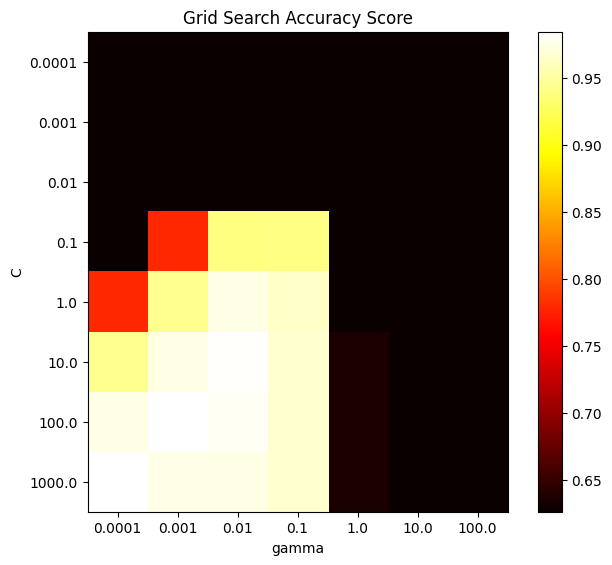

In [10]:
import matplotlib.pyplot as plt
import numpy as np
scores = gs.cv_results_['mean_test_score'][len(param_range):].reshape(len(param_range),len(param_range2))

plt.figure(figsize=(8, 6))
plt.subplots_adjust(left=.2, right=0.95, bottom=0.15, top=0.95)
plt.imshow(scores, interpolation='nearest', cmap=plt.cm.hot)
plt.xlabel('gamma') # 1/(softness of decision boundary), i.e. small = soft
plt.ylabel('C')     # 1/(size of support vector margin), i.e. large = tight margin
plt.colorbar()
plt.xticks(np.arange(len(param_range2)), param_range2)
plt.yticks(np.arange(len(param_range)), param_range)
plt.title('Grid Search Accuracy Score')
plt.show()

### Try: Copy, paste and:
- Finetune in promising area (only RBF)
- Plot results

In [ ]:
## Remove this solution
param_range  = list(np.logspace(1,3,257)) # For regularization parameter C.
param_range2 = list(np.logspace(-4,-1,385))         # For scaling parameter gamma og rbf-kernel.

param_grid   = [{'svc__C': param_range, 'svc__kernel': ['linear']},
                {'svc__C': param_range, 'svc__gamma': param_range2, 'svc__kernel': ['rbf']}]

gs = GridSearchCV(estimator=pipe_svc,
                  param_grid=param_grid,
                  scoring='accuracy',
                  cv=10,
                  n_jobs=-1)

gs = gs.fit(X_train, y_train)
print(gs.best_score_)
print(gs.best_params_)

0.9890821256038647
{'svc__C': 20.169145547303305, 'svc__gamma': 0.0289026391002245, 'svc__kernel': 'rbf'}


Back to presentation

### [Randomized search](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
Random sampling of parameter values

In [13]:
import numpy as np
import scipy.stats as stats
from scipy.stats import loguniform


from sklearn.model_selection import RandomizedSearchCV

# param_range  = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0] # For regularization parameter C.
# param_range2 = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]         # For scaling parameter gamma og rbf-kernel.
#

# Specify parameters and distributions to sample from
param_dist1 = loguniform(1e-4, 1e3)
param_dist2 = loguniform(1e-4, 1e2)
param_grid   = [{'svc__C': param_dist1, 'svc__kernel': ['linear']},
                {'svc__C': param_dist1, 'svc__gamma': param_dist2, 'svc__kernel': ['rbf']}]

# run randomized search
n_iter_search = 20
random_search = RandomizedSearchCV(pipe_svc,
                                   param_distributions=param_grid,
                                   n_iter=n_iter_search,
                                   cv=5)

random_search = random_search.fit(X_train, y_train)
print(random_search.best_score_)
print(random_search.best_params_)

0.9780219780219781
{'svc__C': np.float64(1.1237134670934523), 'svc__kernel': 'linear'}


In [14]:
# Compare with grid search results:
print(gs.best_score_)
print(gs.best_params_)

0.9846859903381642
{'svc__C': 100.0, 'svc__gamma': 0.001, 'svc__kernel': 'rbf'}


#### Build classifier based on all training samples using the "optimal parameters":

In [15]:
clf = random_search.best_estimator_
clf.fit(X_train, y_train)
print('Test accuracy: %.3f' % clf.score(X_test, y_test))
# ... or:
#gs.decision_function(X_train) # (tedious)
print('Test accuracy: %.3f' % random_search.score(X_test, y_test))

Test accuracy: 0.965
Test accuracy: 0.965


### Inspect path of random search

In [16]:
random_search.cv_results_

{'mean_fit_time': array([0.05053353, 0.03136964, 0.01799178, 0.03440771, 0.06379104,
        0.0696547 , 0.01801996, 0.02736406, 0.01265864, 0.01369619,
        0.01945815, 0.02234192, 0.02199264, 0.02589073, 0.01496067,
        0.01940622, 0.01345391, 0.01843381, 0.01313152, 0.0156466 ]),
 'std_fit_time': array([1.71735458e-02, 8.53129178e-03, 3.88733603e-03, 1.50666385e-02,
        2.02663884e-02, 1.59496286e-02, 6.72753295e-03, 9.39384021e-03,
        5.46525886e-03, 9.81975166e-03, 6.76646199e-03, 1.21806915e-02,
        6.55083259e-03, 5.23878608e-03, 7.11382627e-03, 9.60101461e-03,
        4.90430538e-04, 2.78285317e-03, 5.50965889e-05, 3.25109408e-03]),
 'mean_score_time': array([0.01366119, 0.01014652, 0.00400972, 0.01484904, 0.00973191,
        0.02206888, 0.00921712, 0.00964594, 0.00279336, 0.00434213,
        0.00745239, 0.0096221 , 0.01252522, 0.00559611, 0.00768585,
        0.00647116, 0.00581012, 0.00806384, 0.00621824, 0.00715127]),
 'std_score_time': array([0.00844595, 

Back to presentation

### Nested cross-validation¶
Modelling with SVC-classifier:

In [17]:
from sklearn.model_selection import cross_val_score
import time

param_range  = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0] # For regularization parameter C.
param_range2 = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]         # For scaling parameter gamma of the rbf-kernel.

inner_segments = 5
outer_segments = 5

param_grid   = [{'svc__C': param_range, 'svc__kernel': ['linear']},
                {'svc__C': param_range, 'svc__gamma': param_range2, 'svc__kernel': ['rbf']}]

# Inner loop
gs = GridSearchCV(estimator  = pipe_svc,
                  param_grid = param_grid,
                  scoring    = 'accuracy',
                  cv         = inner_segments)

t1 = time.time()
# Outer loop
scores = cross_val_score(gs, X_train, y_train,
                         scoring='accuracy', cv=outer_segments)
t2 = time.time()

n_models = inner_segments*outer_segments*64
print('Total time: %.3fs, time per model: %.3fs' % (t2-t1, (t2-t1)/n_models))
print('Number of models (segments x parameters): %d' % (n_models))
print('CV accuracy: %.3f +/- %.3f' % (np.mean(scores),
                                      np.std(scores)))

Total time: 17.634s, time per model: 0.011s
Number of models (segments x parameters): 1600
CV accuracy: 0.971 +/- 0.023


### Nested cross-validation
Modelling with DecisionTree-classifier:

In [18]:
from sklearn.tree import DecisionTreeClassifier
DTC_pipe = make_pipeline(DecisionTreeClassifier(random_state=0))
DTC_pipe.get_params()

{'memory': None,
 'steps': [('decisiontreeclassifier', DecisionTreeClassifier(random_state=0))],
 'transform_input': None,
 'verbose': False,
 'decisiontreeclassifier': DecisionTreeClassifier(random_state=0),
 'decisiontreeclassifier__ccp_alpha': 0.0,
 'decisiontreeclassifier__class_weight': None,
 'decisiontreeclassifier__criterion': 'gini',
 'decisiontreeclassifier__max_depth': None,
 'decisiontreeclassifier__max_features': None,
 'decisiontreeclassifier__max_leaf_nodes': None,
 'decisiontreeclassifier__min_impurity_decrease': 0.0,
 'decisiontreeclassifier__min_samples_leaf': 1,
 'decisiontreeclassifier__min_samples_split': 2,
 'decisiontreeclassifier__min_weight_fraction_leaf': 0.0,
 'decisiontreeclassifier__monotonic_cst': None,
 'decisiontreeclassifier__random_state': 0,
 'decisiontreeclassifier__splitter': 'best'}

In [19]:
param_grid=[{'decisiontreeclassifier__max_depth': [1, 2, 3, 4, 5, 6, 7, None]}]

# Inner loop
gs = GridSearchCV(estimator  = DTC_pipe,
                  param_grid = param_grid,
                  scoring    = 'accuracy',
                  cv         = inner_segments)
t1 = time.time()
# Outer loop
scores = cross_val_score(gs, X_train, y_train,
                         scoring='accuracy', cv=outer_segments)
t2 = time.time()

n_models = inner_segments*outer_segments*8
print('Total time: %.3fs, time per model: %.3fs' % (t2-t1, (t2-t1)/n_models))
print('Number of models (segments x parameters): %d' % (n_models))
print('CV accuracy: %.3f +/- %.3f' % (np.mean(scores),
                                      np.std(scores)))

Total time: 2.173s, time per model: 0.011s
Number of models (segments x parameters): 200
CV accuracy: 0.927 +/- 0.018


### Manual outer loop
Assess stability of parameters

In [20]:
from sklearn.model_selection import StratifiedKFold
kfold = StratifiedKFold(n_splits=5).split(X_train, y_train)

for k, (train, test) in enumerate(kfold):
    # GridSearchCV with inner splitting
    gs.fit(X_train[train,:],y_train[train])

    # Inner results
    param   = gs.cv_results_['param_decisiontreeclassifier__max_depth'][np.argmax(gs.cv_results_['mean_test_score'])]
    in_acc  = round(np.max(gs.cv_results_['mean_test_score']),4)

    # Outer accuracy
    out_acc = round(gs.score(X_train[test,:], y_train[test]),4)

    # Print
    print('Chosen max_depth: ' + str(param) \
         + ', with accuracies: ' + str(in_acc) + ', ' + str(out_acc))

Chosen max_depth: 5, with accuracies: 0.9479, 0.9121
Chosen max_depth: None, with accuracies: 0.9506, 0.9451
Chosen max_depth: 5, with accuracies: 0.9451, 0.9011
Chosen max_depth: 3, with accuracies: 0.9424, 0.9341
Chosen max_depth: 4, with accuracies: 0.9313, 0.9451


Back to presentation